In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import read_csv
import math
import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from keras.layers import Dense, Activation, Dropout
import time #helper libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import read_csv
import math
import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from keras.layers import Dense, Activation, Dropout
import time #helper libraries
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory
import itertools
from sklearn.metrics import mean_absolute_error, r2_score, mean_absolute_percentage_error
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
import os
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score
import itertools
from sklearn.metrics import accuracy_score, classification_report
import keras_tuner as kt
from tensorflow.keras.optimizers import Adam
import os

'''
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
'''
# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

2026-05-06 20:16:15.433884: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-05-06 20:16:15.445721: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-05-06 20:16:15.537667: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-05-06 20:16:15.537710: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-05-06 20:16:15.537745: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to regi

"\nfor dirname, _, filenames in os.walk('/kaggle/input'):\n    for filename in filenames:\n        print(os.path.join(dirname, filename))\n"

In [2]:
#df= pd.read_csv("processed_news_scores_with_stocks_WITH_AGGREGATE_ready_formodeling.csv")
#score_cols = [f"scores_{i}" for i in range(23)]
#df = df.drop(columns=score_cols)
df_tesla = pd.read_csv("Tesla_processed_news_scores_with_stocks_WITH_AGGREGATE_ready_formodeling.csv")
df_apple= pd.read_csv("Apple_processed_news_scores_with_stocks_WITH_AGGREGATE_ready_formodeling.csv")
df_amazon= pd.read_csv("Amazon_processed_news_scores_with_stocks_WITH_AGGREGATE_ready_formodeling.csv")

In [3]:
df_tesla = df_tesla.sort_values(by="timestamp").reset_index(drop=True)
df_apple = df_apple.sort_values(by="timestamp").reset_index(drop=True)
df_amazon = df_amazon.sort_values(by="timestamp").reset_index(drop=True)


In [4]:
df_tesla.isna().any()

timestamp              False
close                  False
day                    False
hour                   False
avg_norm_avg_scores    False
avg_norm_max_scores    False
avg_norm_min_scores    False
dtype: bool

In [5]:
df_tesla['close_sign'] = (df_tesla['close'] > df_tesla['close'].shift(1)).astype(int)
df_tesla['close_diff'] = (df_tesla['close'].diff()).astype(float)
df_tesla['close_diff'] = df_tesla['close_diff'].fillna(0)


df_apple['close_sign'] = (df_apple['close'] > df_apple['close'].shift(1)).astype(int)
df_apple['close_diff'] = (df_apple['close'].diff()).astype(float)
df_apple['close_diff'] = df_apple['close_diff'].fillna(0)



df_amazon['close_sign'] = (df_amazon['close'] > df_amazon['close'].shift(1)).astype(int)
df_amazon['close_diff'] = (df_amazon['close'].diff()).astype(float)
df_amazon['close_diff'] = df_amazon['close_diff'].fillna(0)


# LSTM

## Close price with avg min, and max score of all. 

In [6]:
# convert an array of values into a dataset matrix
def create_dataset(dataset, look_back=1, target_col=0):
    dataX, dataY = [], []
    for i in range(len(dataset)-look_back-1):
        a = dataset[i:(i+look_back), :]          # full feature window
        dataX.append(a)
        dataY.append(dataset[i + look_back, target_col])
    return np.array(dataX), np.array(dataY)




#### Changes implemented on nov 30 code:
1- Adding stopping epochs. 

2- add validation dataset

3- NO NORMALIZATION to target . ALL ARE WITHIN 0 AND 1. only normalize features. 

4- Adding evaluation metrics 

5- close diff is added to features. 

Limitations to note:
- the time series, does not have same interval gaps due to market closure, for example some datapoints might have 1 hour gaps while others have 9. News are accumulated within the 9 hours of market closure and treated equally. otherwise the datapoint gaps are treated similarly. 

In [7]:
#######################NEW###########################
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=20,        # stops if no improvement for 20 epochs
    restore_best_weights=True
)


#######################NEW###########################



=== Hypertuning Tesla (classification multivariate) ===


2026-05-06 20:17:07.071655: E tensorflow/compiler/xla/stream_executor/cuda/cuda_driver.cc:268] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


Best for Tesla: {'n_layers': 1, 'units': 25, 'dropout': 0.1, 'lr': 0.001}
Tesla 15 0.6
293/293 [==============================] - 1s 4ms/step
Tesla 15 0.7
219/219 [==============================] - 1s 4ms/step
Tesla 15 0.8
146/146 [==============================] - 1s 5ms/step
Tesla 30 0.6
292/292 [==============================] - 2s 5ms/step
Tesla 30 0.7
219/219 [==============================] - 1s 6ms/step
Tesla 30 0.8
146/146 [==============================] - 1s 7ms/step
Tesla 45 0.6
292/292 [==============================] - 3s 9ms/step
Tesla 45 0.7
511/511 [==============================] - 5s 8ms/step


219/219 [==============================] - 2s 8ms/step
Tesla 45 0.8
145/145 [==============================] - 1s 6ms/step


/home/dem1110/.local/lib/python3.11/site-packages/sklearn/metrics/_plot/confusion_matrix.py:143: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots()


145/145 [==============================] - 1s 6ms/step
Tesla 60 0.6
291/291 [==============================] - 2s 8ms/step
Tesla 60 0.7
218/218 [==============================] - 2s 8ms/step
Tesla 60 0.8
145/145 [==============================] - 1s 7ms/step
Tesla 75 0.6
291/291 [==============================] - 3s 9ms/step
Tesla 75 0.7
218/218 [==============================] - 2s 9ms/step
Tesla 75 0.8
144/144 [==============================] - 2s 12ms/step
Tesla 90 0.6
290/290 [==============================] - 4s 13ms/step
Tesla 90 0.7
217/217 [==============================] - 3s 12ms/step


... (7 outputs left out)

Best for Amazon: {'n_layers': 1, 'units': 25, 'dropout': 0.1, 'lr': 0.001}
Amazon 15 0.6
280/280 [==============================] - 6s 20ms/step
Amazon 15 0.7
210/210 [==============================] - 5s 22ms/step
Amazon 15 0.8
140/140 [==============================] - 3s 22ms/step
Amazon 30 0.6
279/279 [==============================] - 6s 22ms/step
Amazon 30 0.7
209/209 [==============================] - 6s 27ms/step
Amazon 30 0.8
139/139 [==============================] - 3s 24ms/step
Amazon 45 0.6
279/279 [==============================] - 7s 26ms/step
Amazon 45 0.7
489/489 [==============================] - 17s 31ms/step


209/209 [==============================] - 5s 24ms/step
Amazon 45 0.8
139/139 [==============================] - 5s 33ms/step
Amazon 60 0.6
278/278 [==============================] - 9s 32ms/step
Amazon 60 0.7
208/208 [==============================] - 7s 35ms/step
Amazon 60 0.8
138/138 [==============================] - 5s 37ms/step
Amazon 75 0.6
278/278 [==============================] - 11s 40ms/step
Amazon 75 0.7
208/208 [==============================] - 3s 13ms/step
Amazon 75 0.8
138/138 [==============================] - 5s 38ms/step


138/138 [==============================] - 5s 37ms/step
Amazon 90 0.6
277/277 [==============================] - 9s 31ms/step
Amazon 90 0.7
207/207 [==============================] - 8s 36ms/step
Amazon 90 0.8
138/138 [==============================] - 6s 43ms/step
Amazon 105 0.6
277/277 [==============================] - 13s 47ms/step
Amazon 105 0.7
207/207 [==============================] - 8s 38ms/step
Amazon 105 0.8
137/137 [==============================] - 5s 35ms/step
Amazon 120 0.6
277/277 [==============================] - 10s 35ms/step


277/277 [==============================] - 11s 40ms/step
Amazon 120 0.7
207/207 [==============================] - 8s 36ms/step
Amazon 120 0.8
137/137 [==============================] - 5s 35ms/step
Amazon 135 0.6
276/276 [==============================] - 9s 31ms/step
Amazon 135 0.7
206/206 [==============================] - 9s 44ms/step
Amazon 135 0.8
136/136 [==============================] - 7s 49ms/step


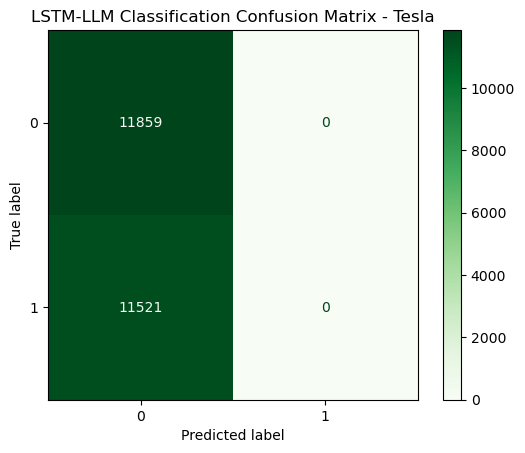

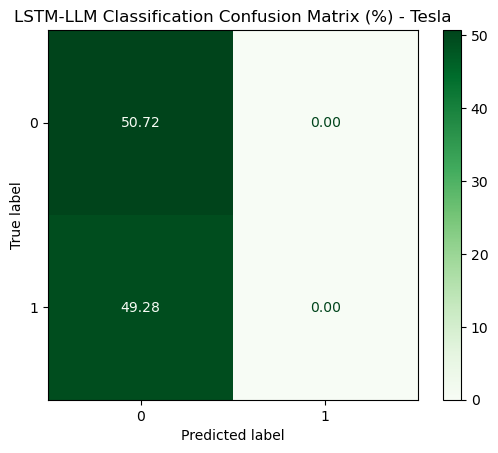

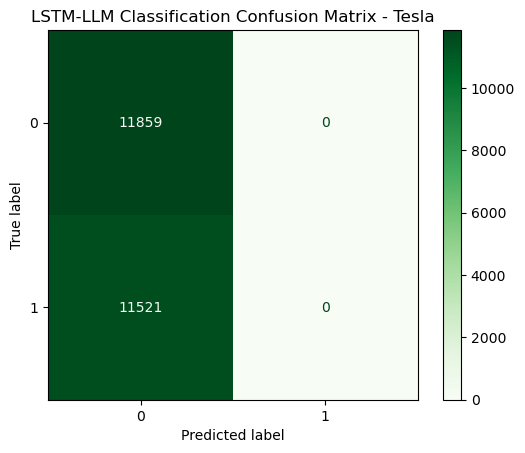

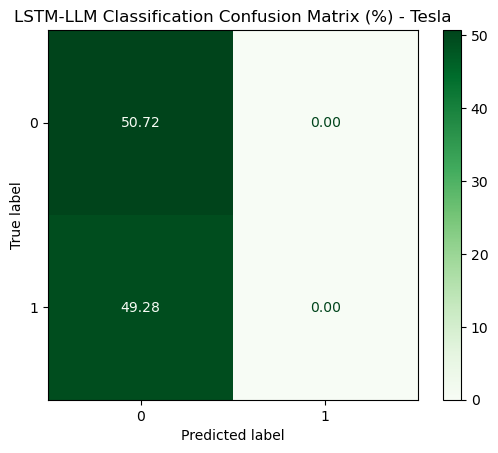

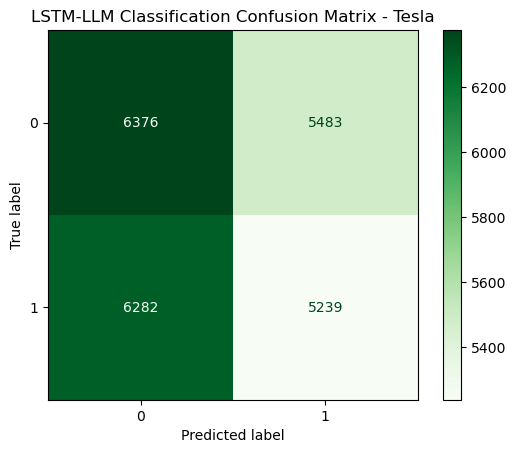

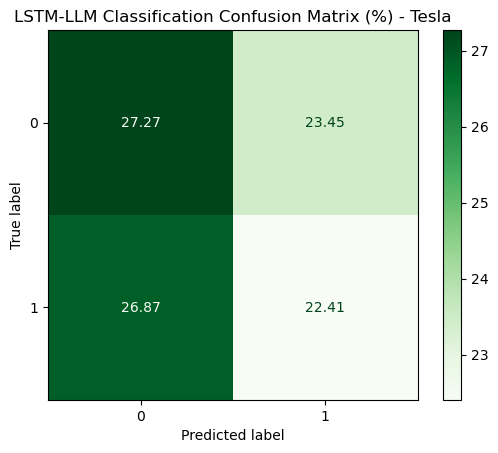

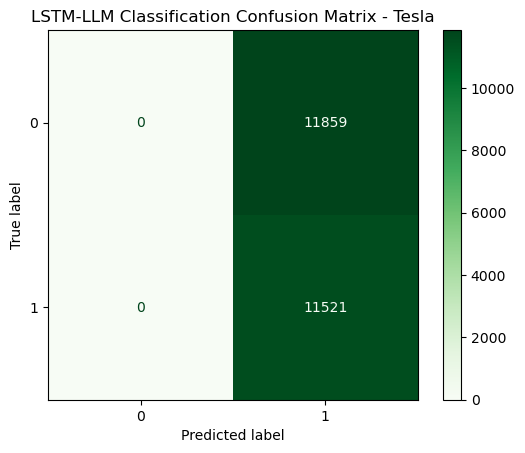

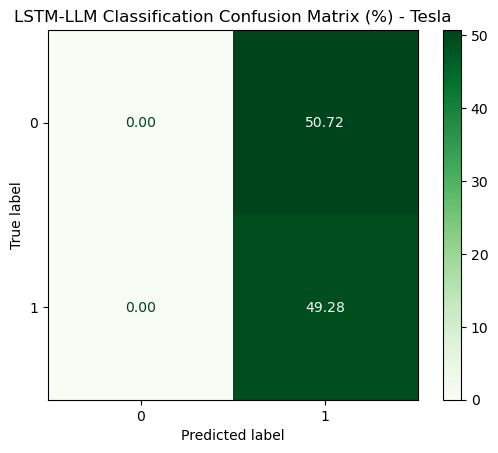

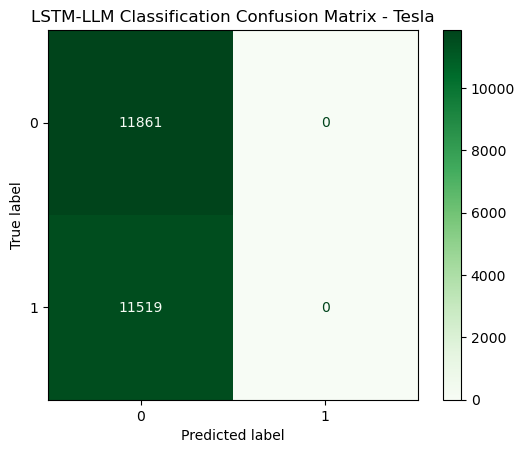

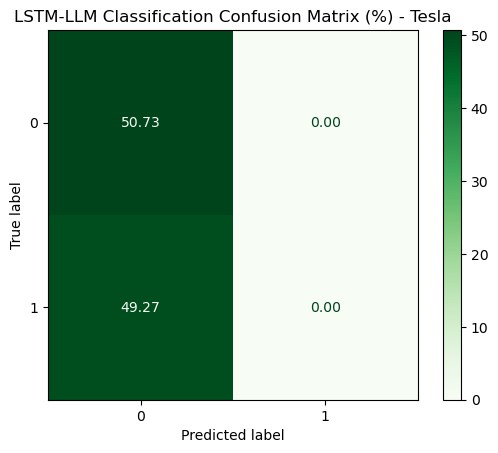

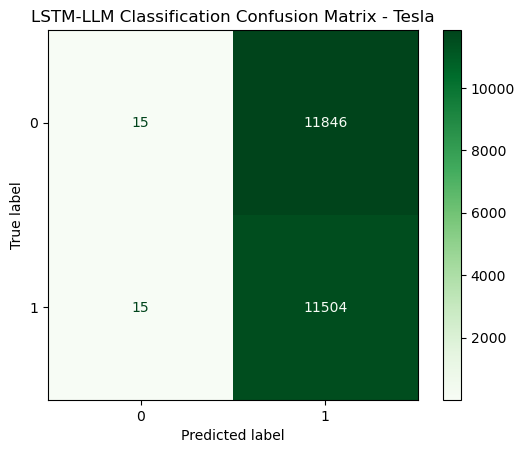

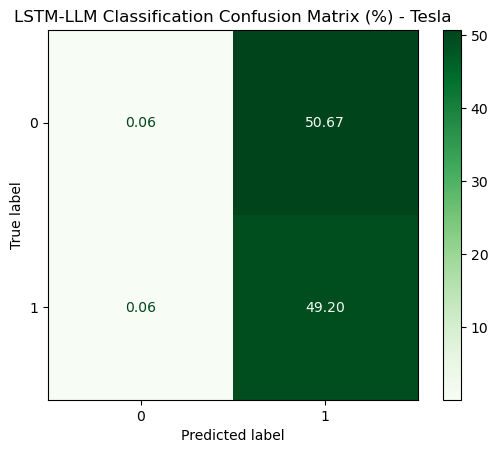

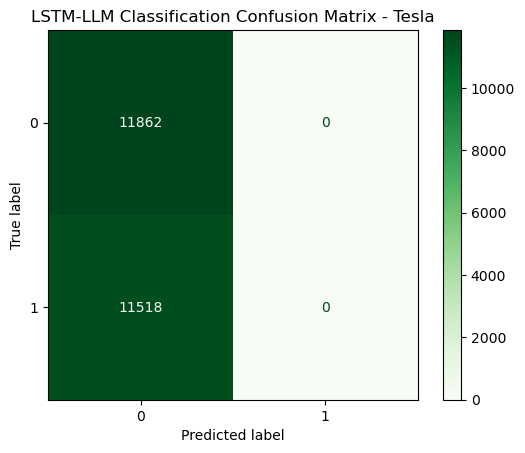

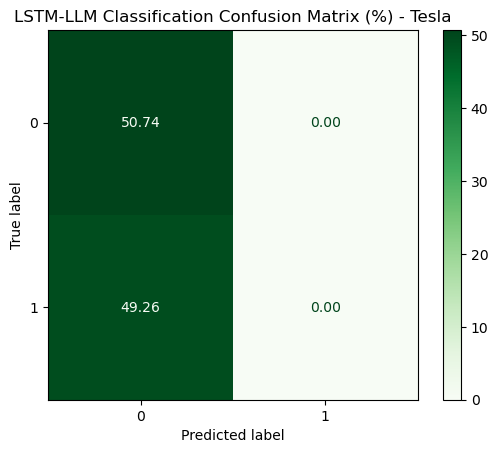

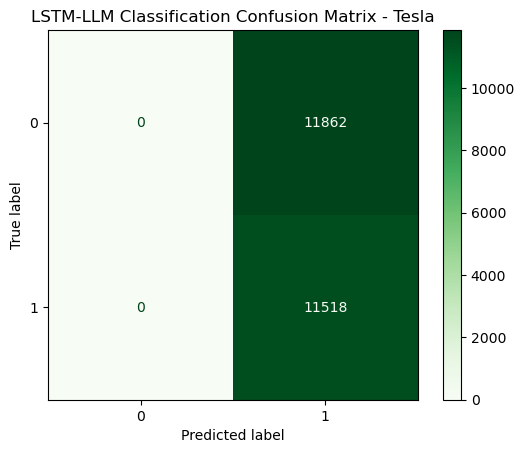

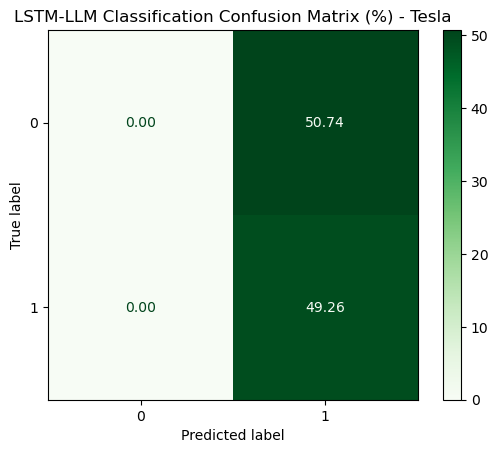

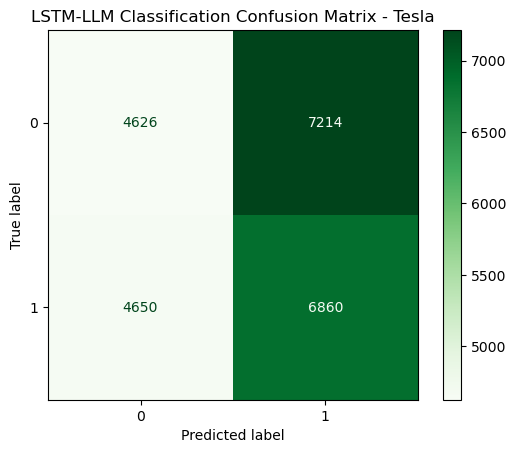

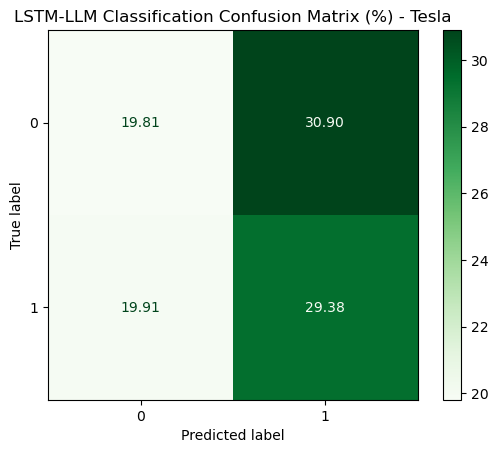

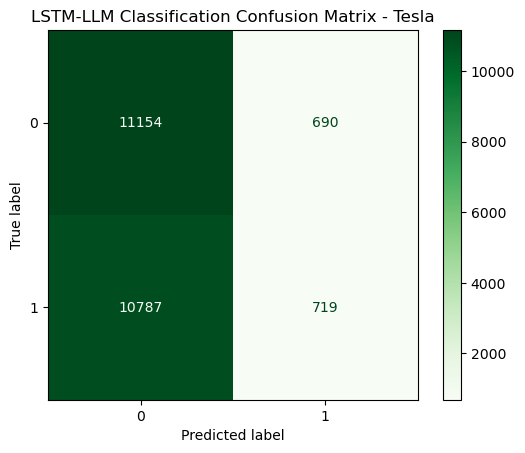

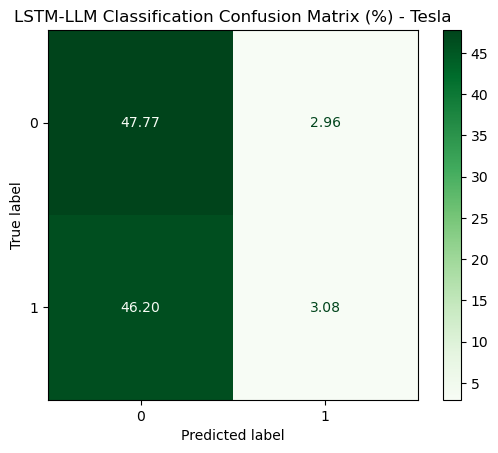

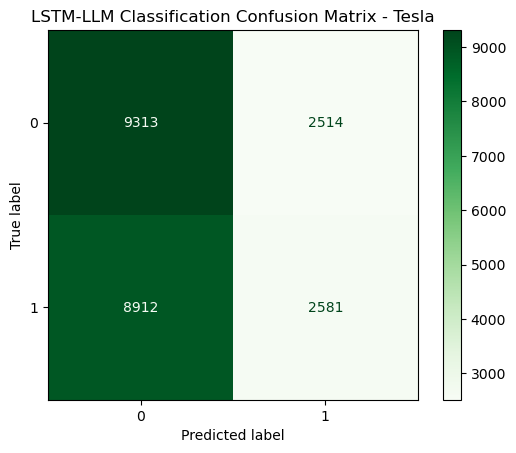

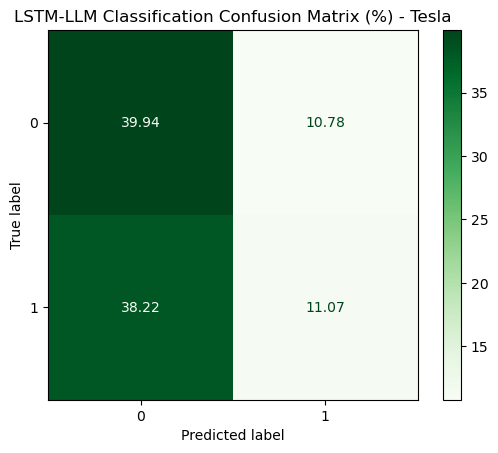

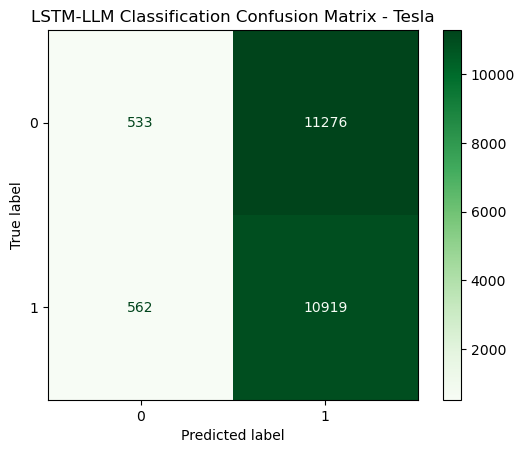

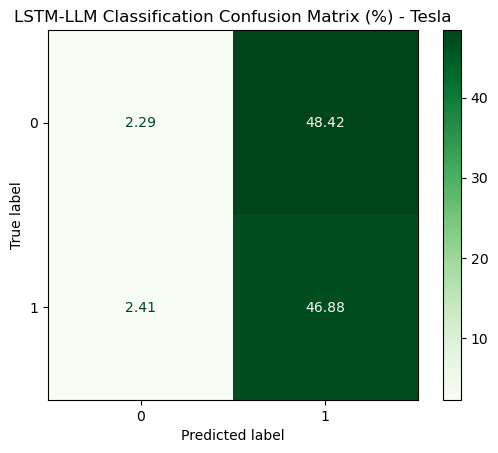

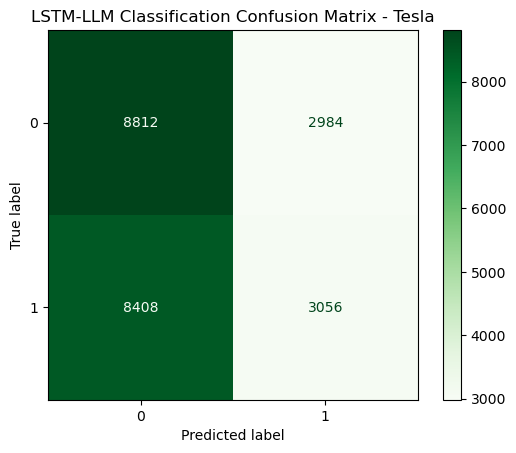

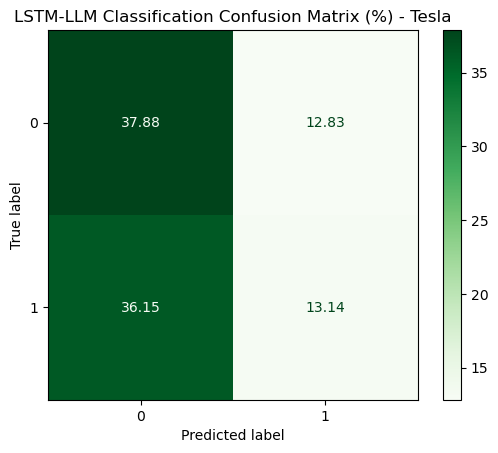

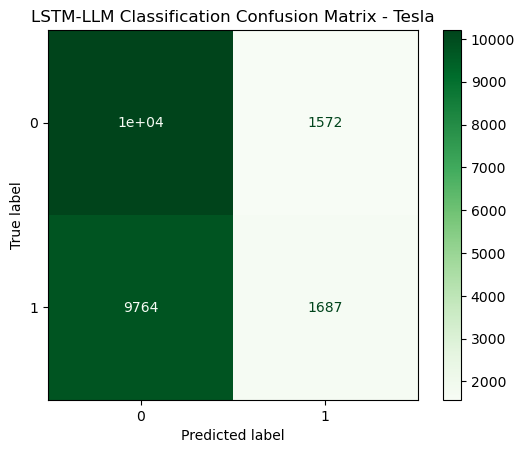

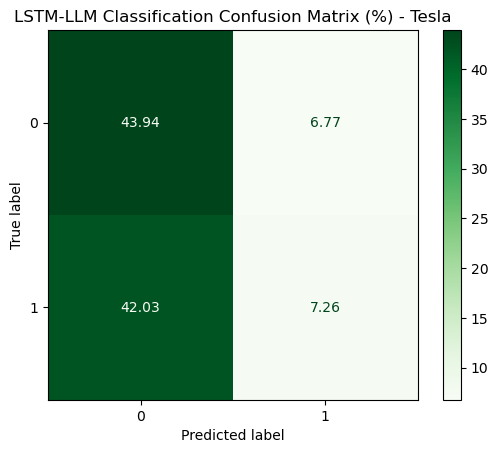

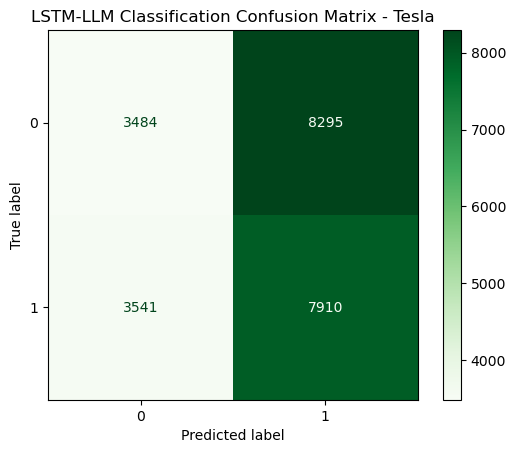

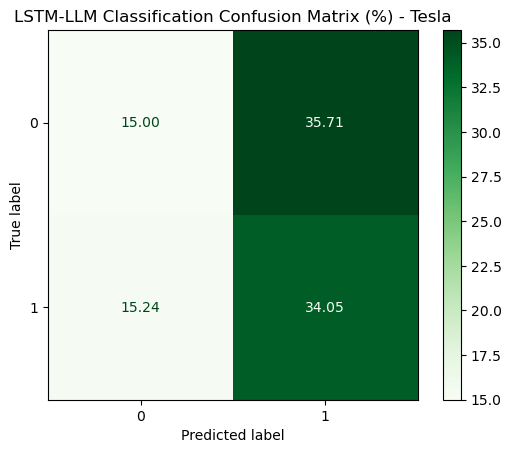

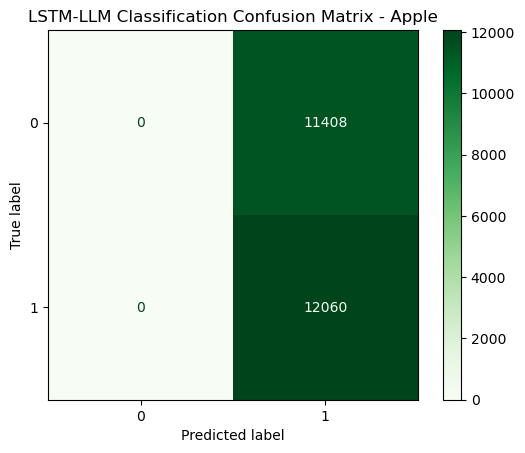

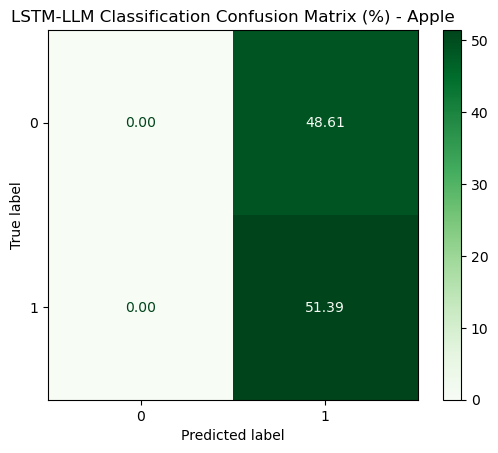

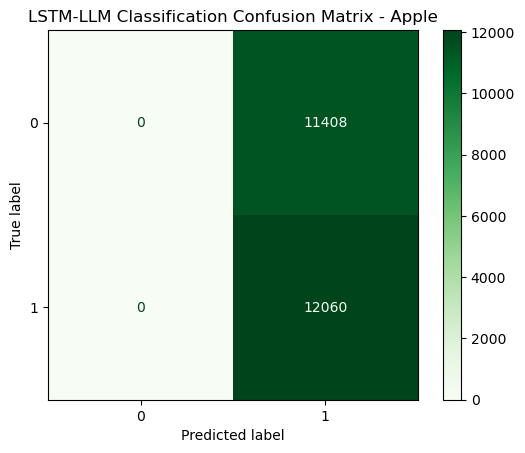

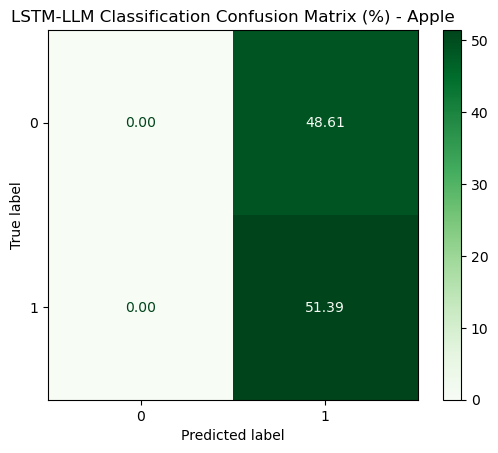

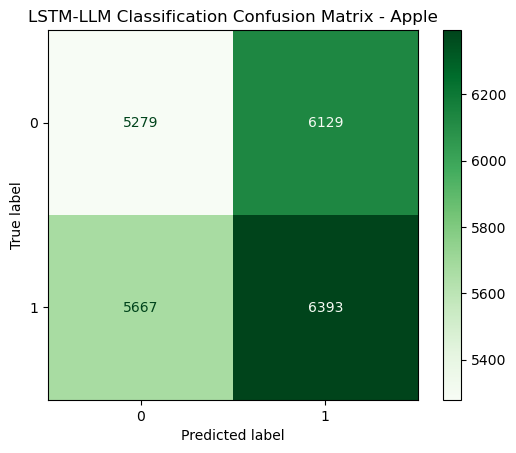

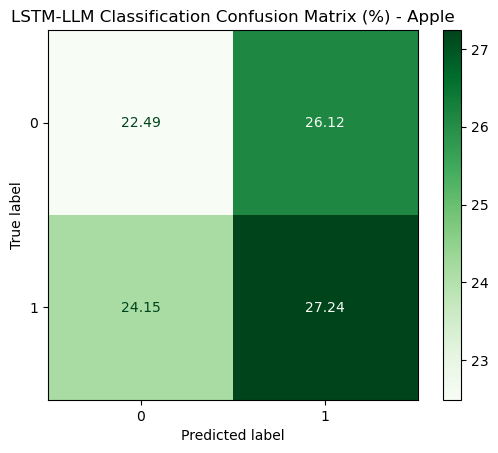

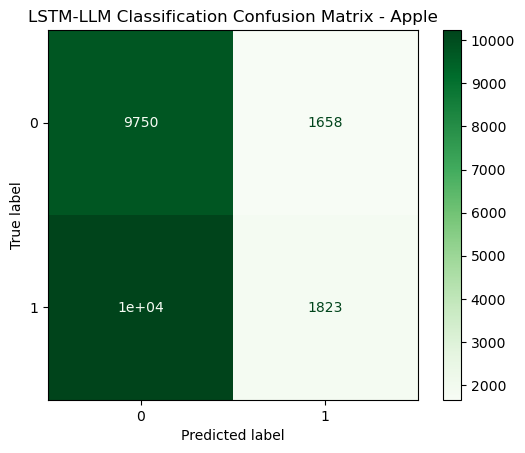

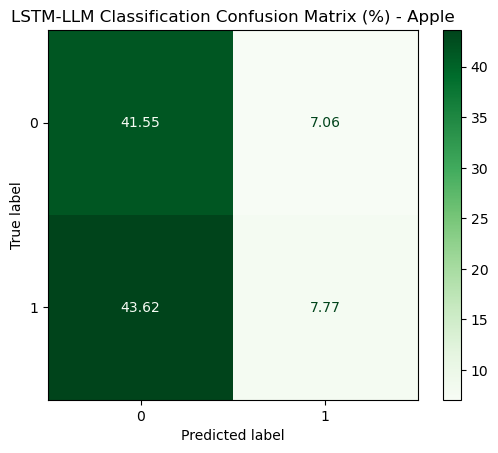

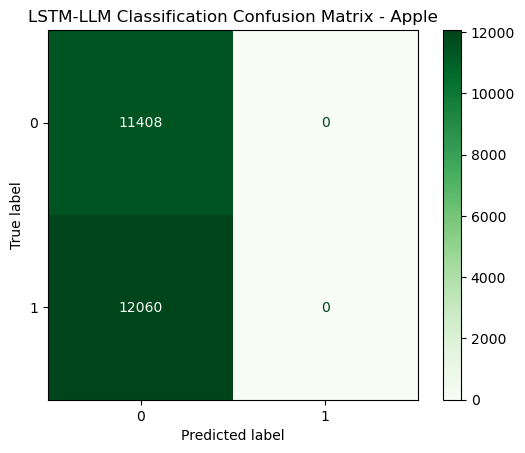

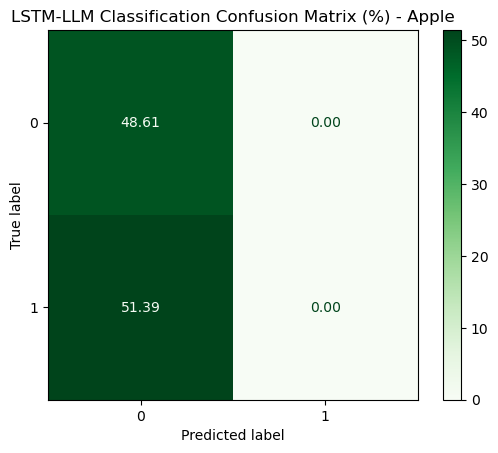

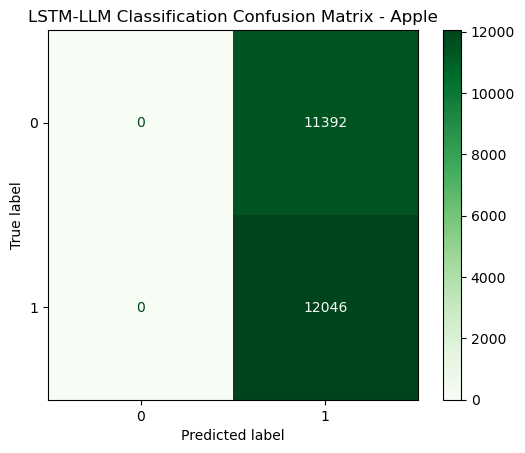

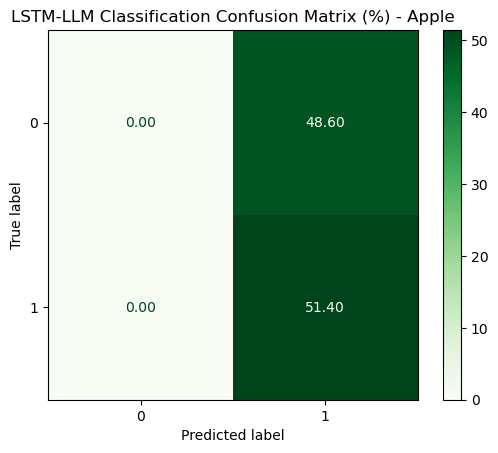

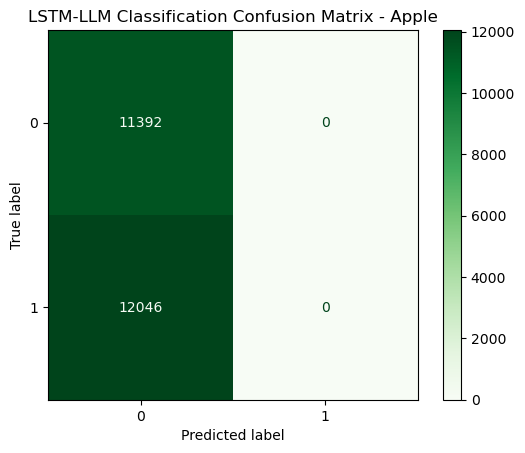

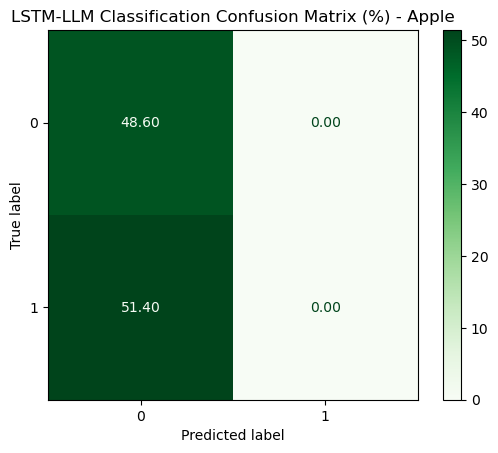

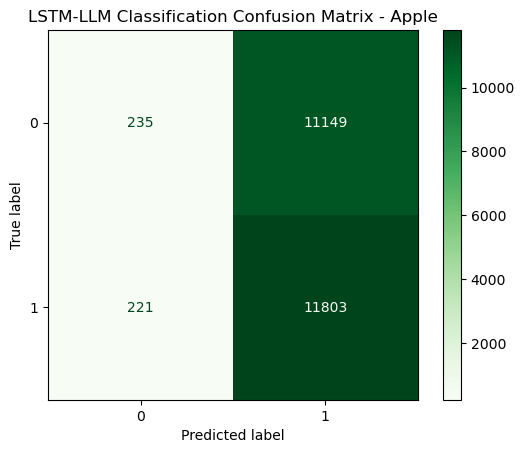

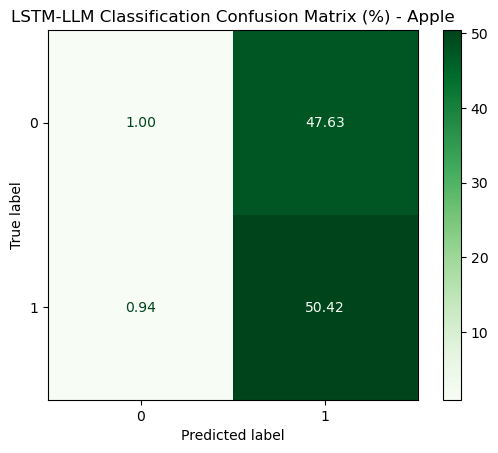

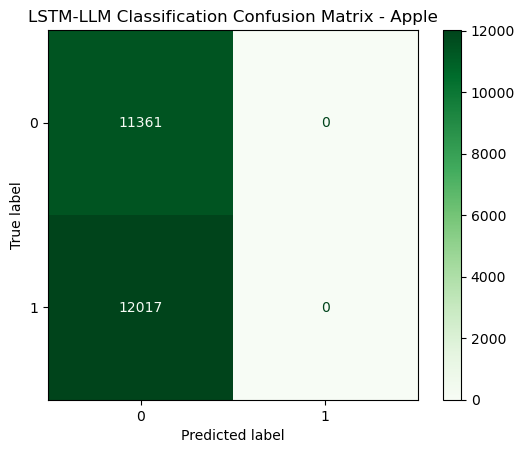

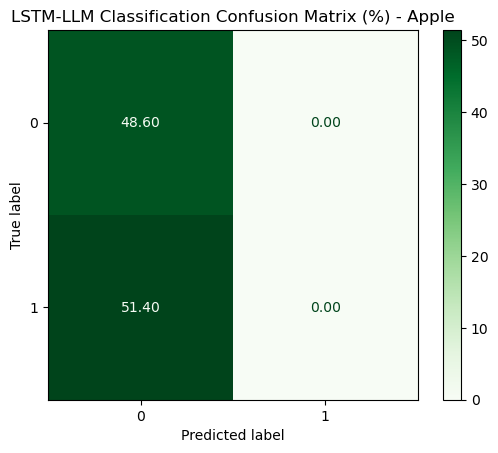

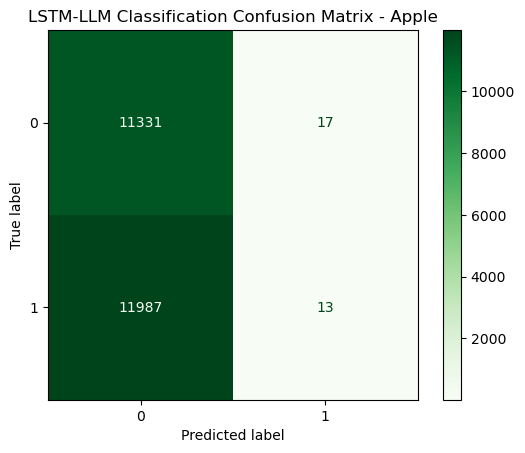

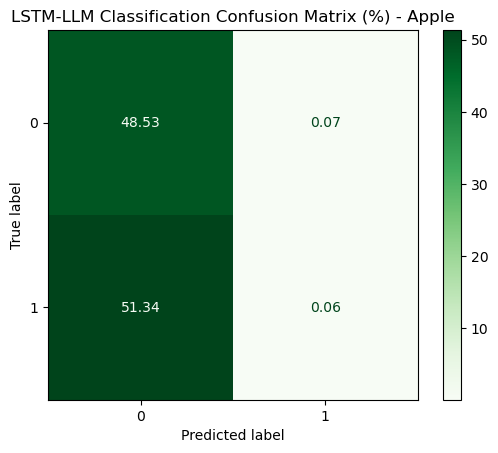

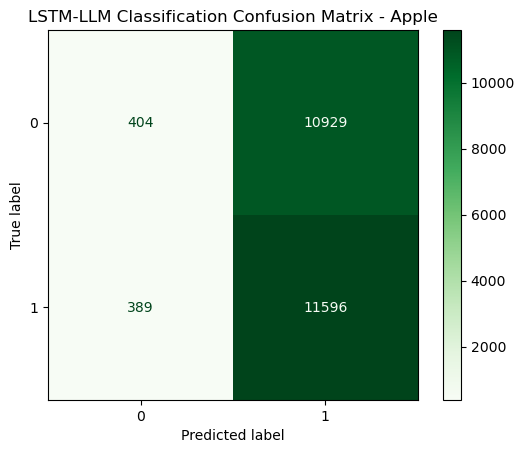

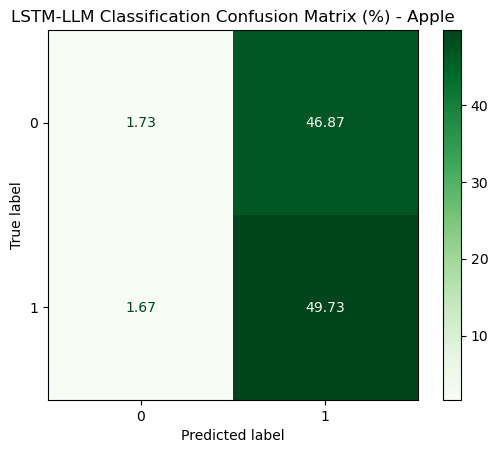

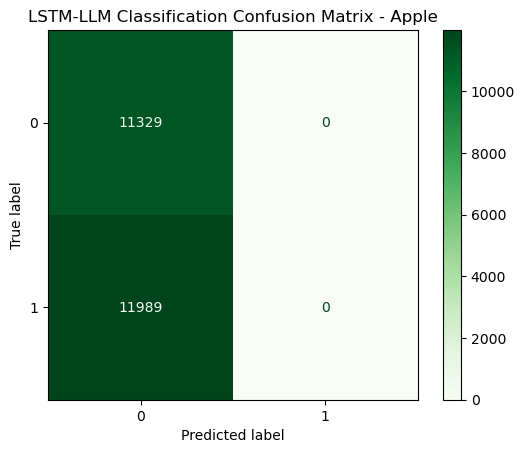

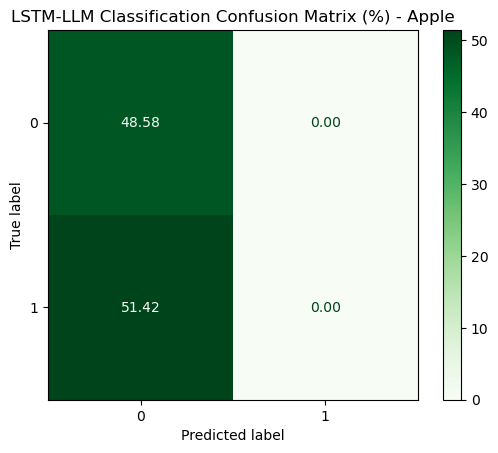

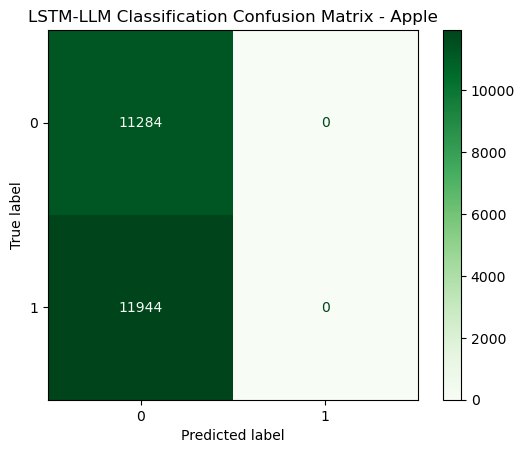

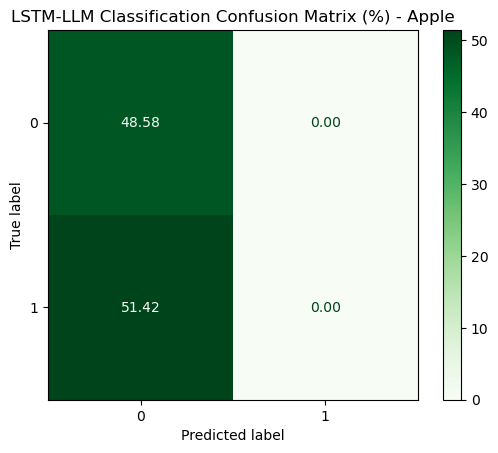

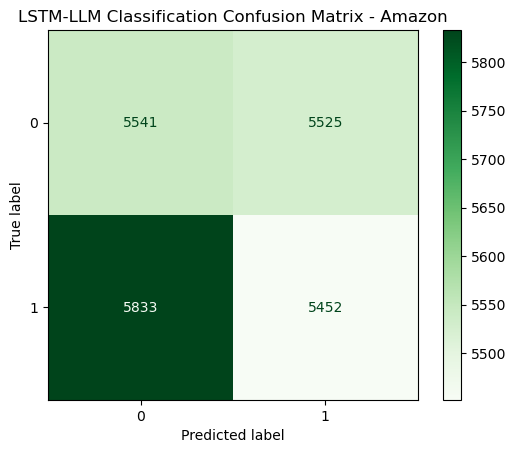

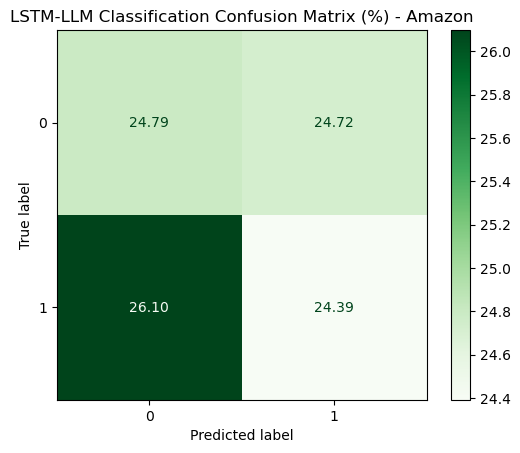

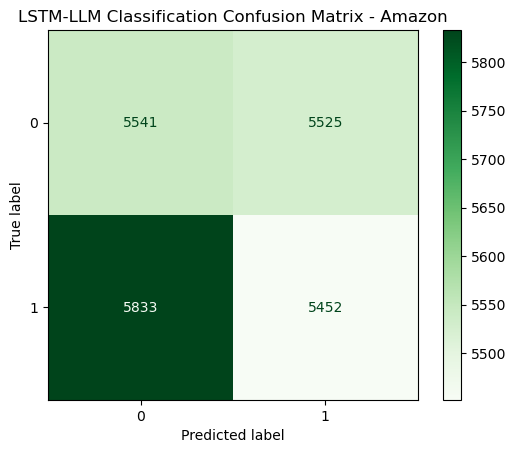

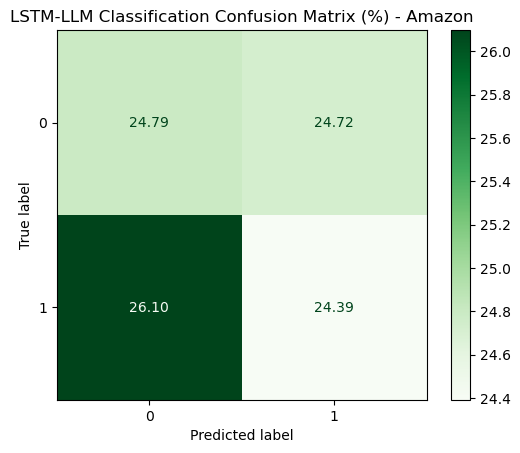

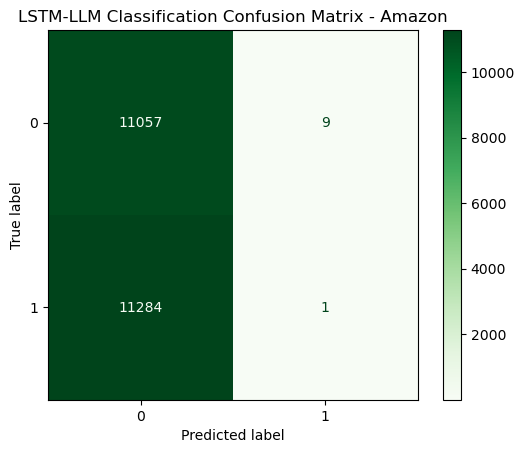

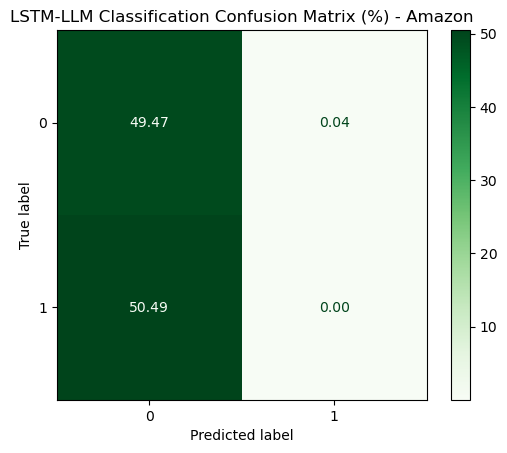

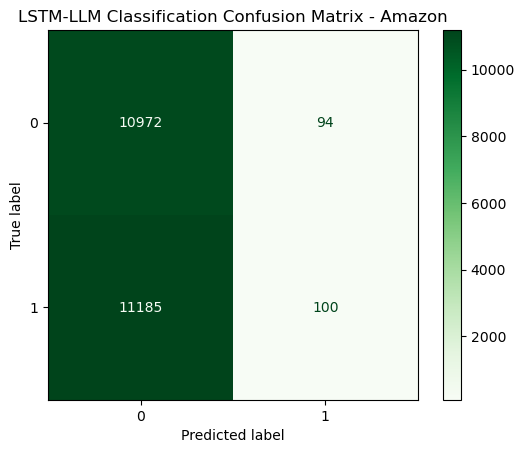

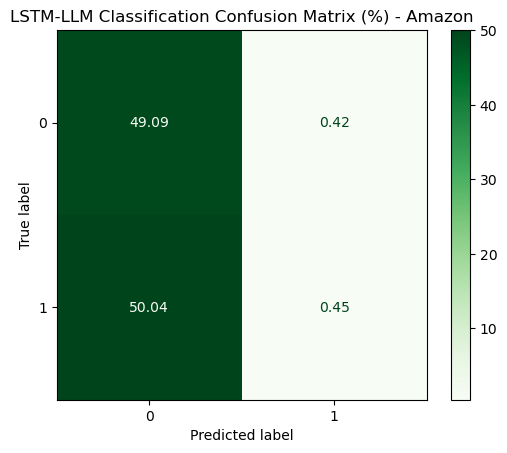

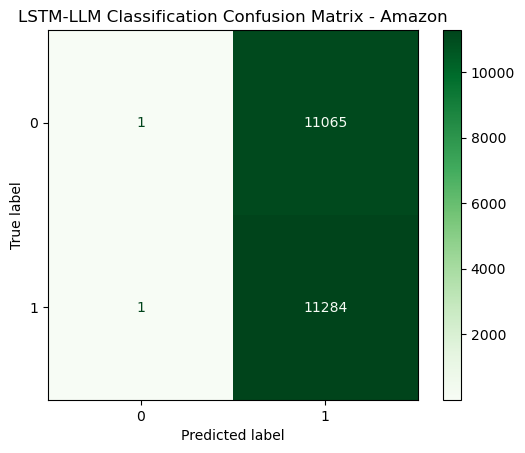

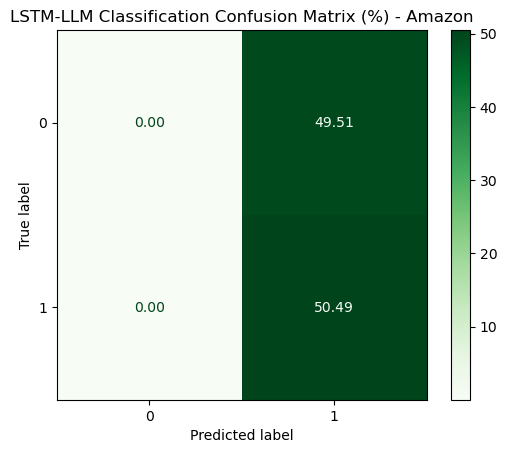

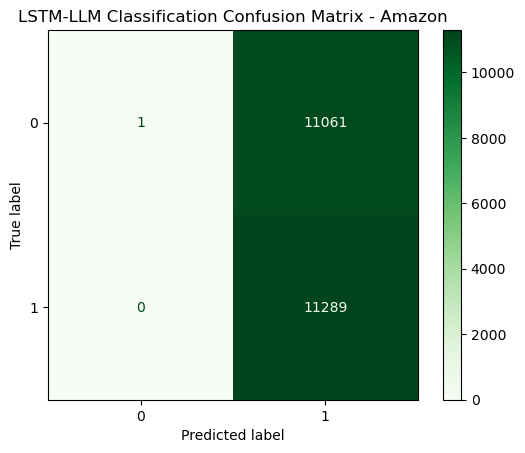

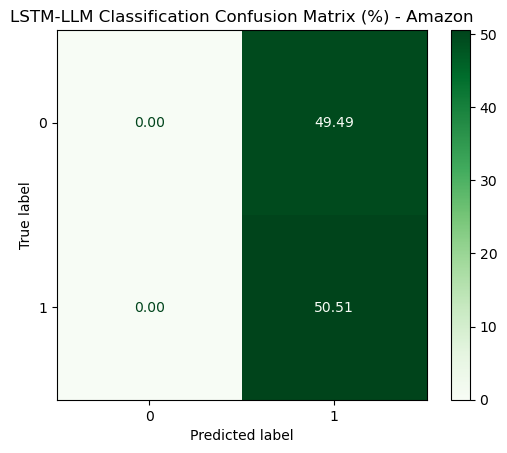

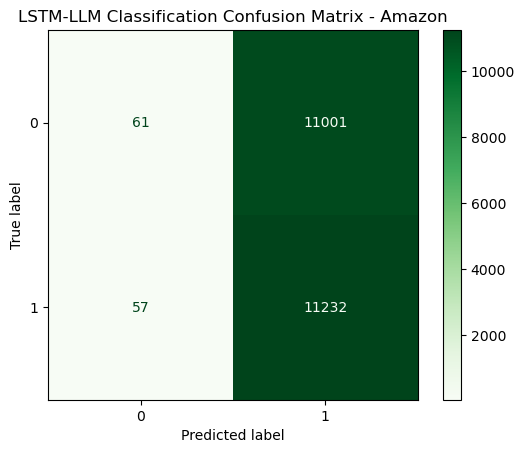

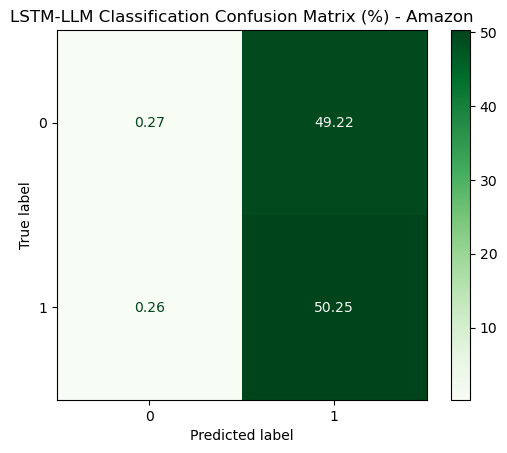

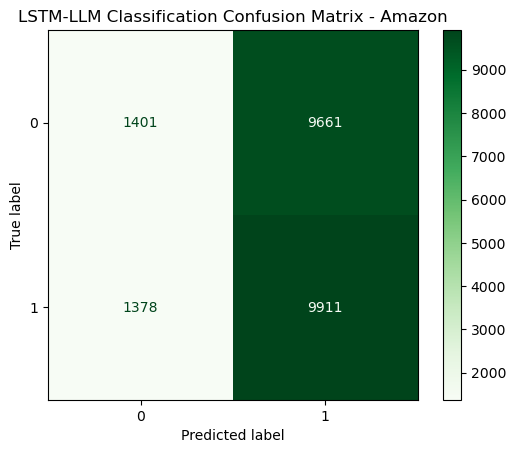

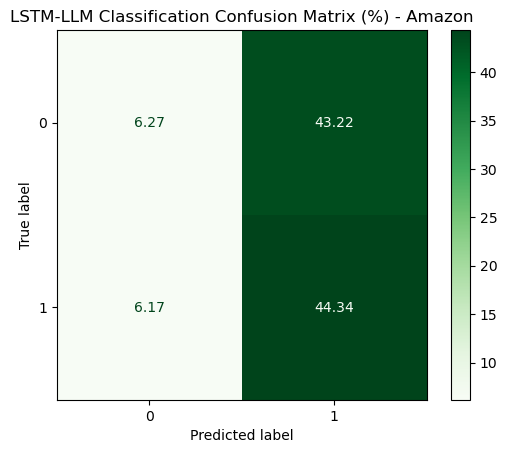

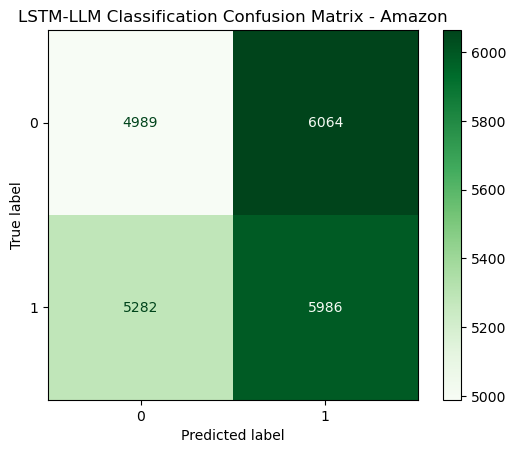

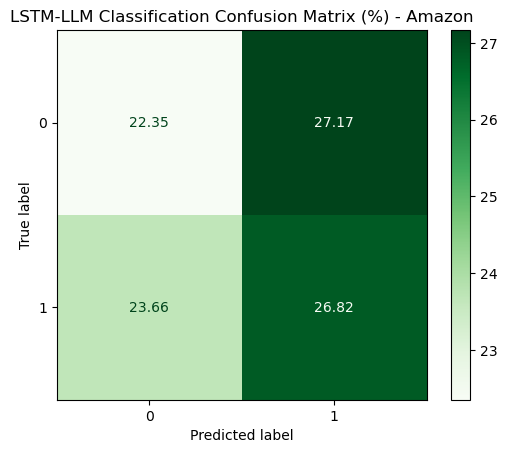

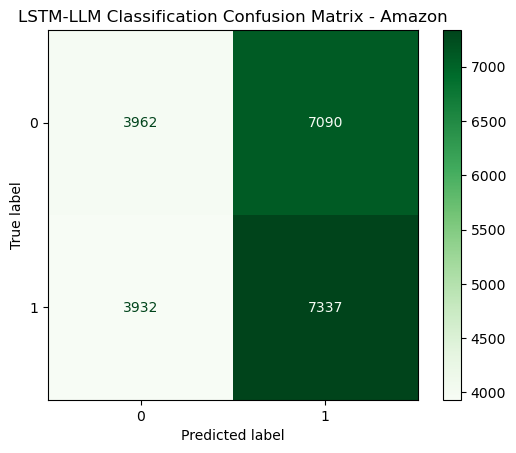

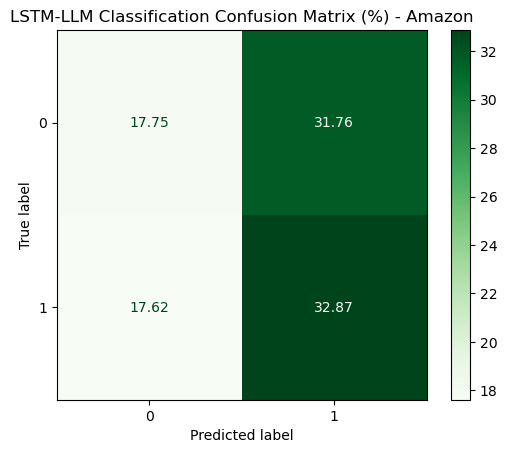

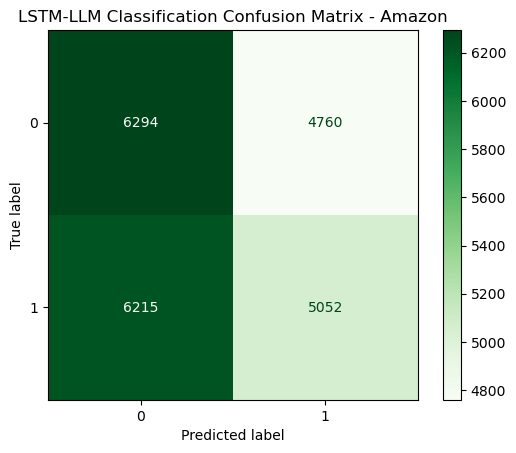

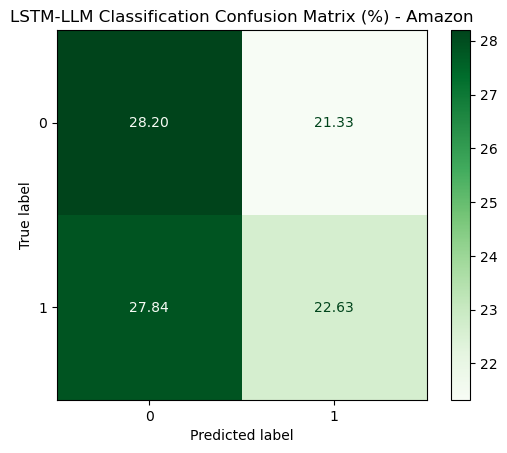

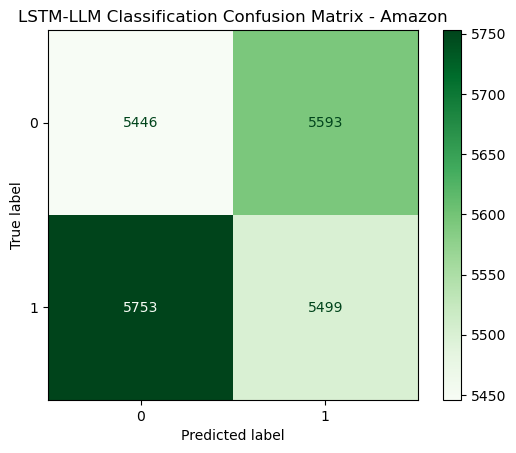

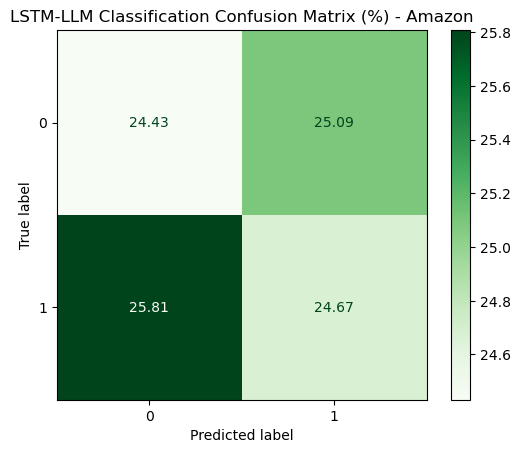

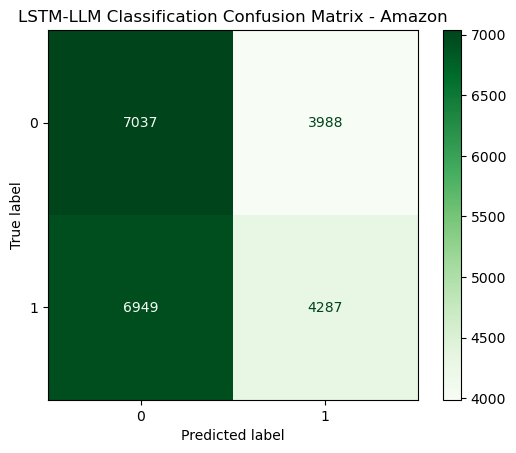

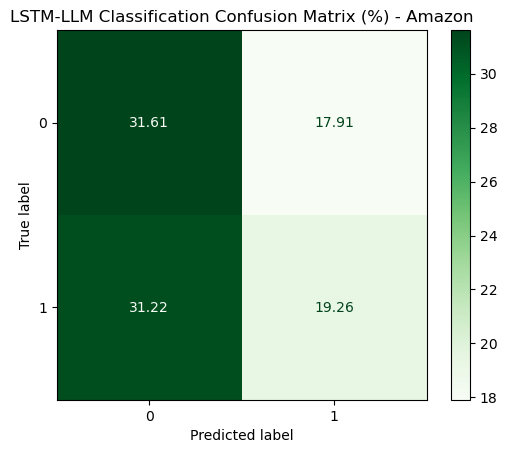

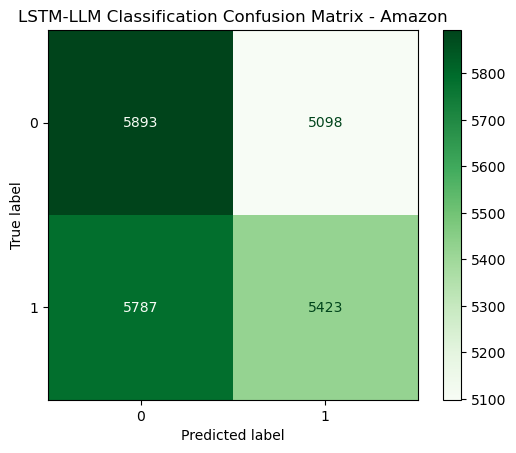

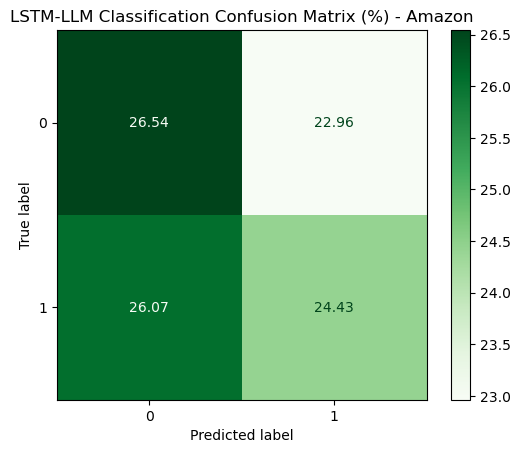

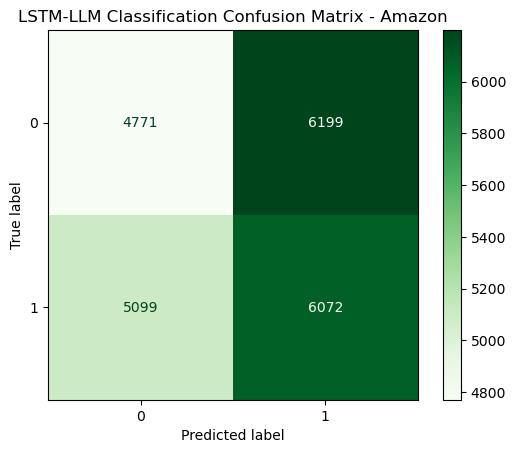

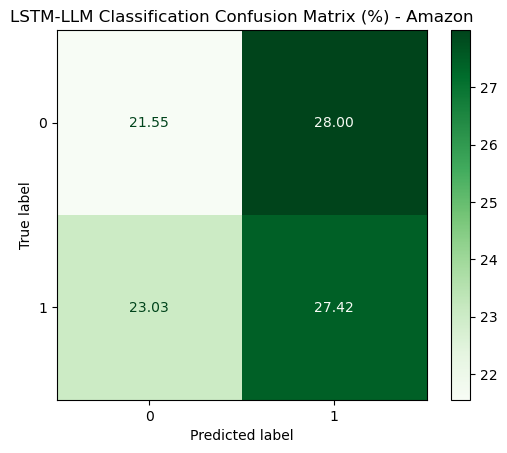

In [8]:
n_repeats = 10
lookbacks = np.arange(15, 150, 15)
train_sizes = [0.6, 0.7, 0.8]
rows = []

# NEW: dictionary mapping company -> dataframe
companies = {
    "Tesla":  df_tesla,
    "Apple":  df_apple,
    "Amazon": df_amazon,
}



# ===== HYPERTUNING SECTION (classification multivariate) =====
cols = ["close_sign", "close_diff", "avg_norm_avg_scores", "avg_norm_max_scores", "avg_norm_min_scores"]
TUNE_LOOKBACK = 30
TUNE_TS = 0.7

best_hyperparams_per_company = {}

for company, df in companies.items():
    print(f"\n=== Hypertuning {company} (classification multivariate) ===")

    dataset = df[cols].values
    target_col = 0

    train_size = int(len(dataset) * TUNE_TS)
    train, test = dataset[0:train_size, :], dataset[train_size:, :]

    # Normalize features only (not close_sign target at col 0)
    scaler = MinMaxScaler(feature_range=(0, 1))
    train[:, 1:] = scaler.fit_transform(train[:, 1:])
    test[:, 1:]  = scaler.transform(test[:, 1:])

    trainX, trainY = create_dataset(train, TUNE_LOOKBACK, target_col)
    n_features = dataset.shape[1]
    trainX = trainX.reshape(trainX.shape[0], TUNE_LOOKBACK, n_features)

    def build_model(hp):
        model = Sequential()
        n_layers = hp.Int("n_layers", 1, 2)
        units    = hp.Choice("units", [25, 50, 100])
        dropout  = hp.Choice("dropout", [0.1, 0.2, 0.3])
        lr       = hp.Choice("lr", [1e-3, 1e-2])

        if n_layers == 1:
            model.add(LSTM(units, input_shape=(TUNE_LOOKBACK, n_features)))
            model.add(Dropout(dropout))
        else:
            model.add(LSTM(units, return_sequences=True, input_shape=(TUNE_LOOKBACK, n_features)))
            model.add(Dropout(dropout))
            model.add(LSTM(units))
            model.add(Dropout(dropout))

        model.add(Dense(1, activation="sigmoid"))
        model.compile(loss="binary_crossentropy", optimizer=Adam(learning_rate=lr), metrics=["accuracy"])
        return model

    tuner = kt.BayesianOptimization(
        build_model,
        objective="val_accuracy",
        max_trials=15,
        directory="nov30_codes_new_data/LSTM-HYPERTUNING",
        project_name=f"clf_multivariate_{company}",
        overwrite=True,
    )

    tuner.search(
        trainX, trainY,
        epochs=50,
        validation_split=0.1,
        batch_size=240,
        callbacks=[early_stop],
        verbose=0,
    )

    best_hp = tuner.get_best_hyperparameters(1)[0]
    best_hyperparams_per_company[company] = {
        "n_layers": best_hp.get("n_layers"),
        "units":    best_hp.get("units"),
        "dropout":  best_hp.get("dropout"),
        "lr":       best_hp.get("lr"),
    }
    print(f"Best for {company}: {best_hyperparams_per_company[company]}")
    ######################################################################################
    best_acc = -float("inf")
    worst_acc = float("inf")
    for lookback, ts in itertools.product(lookbacks, train_sizes):
        print(company, lookback, ts)
        for repeat in range(n_repeats):

            # fix random seed for reproducibility
            np.random.seed(5)

            # take close price column[5]
            dataset = df[['close_sign', 'close_diff','avg_norm_avg_scores', 'avg_norm_max_scores',
                          'avg_norm_min_scores']].values
            target_col = 0  # target label is Close SIGN
            
            

            # split into train and test sets
            train_size = int(len(dataset) * ts)
            train, test = dataset[0:train_size, :], dataset[train_size:, :]
            
            # normalize AFTER split — fit only on train
            scaler = MinMaxScaler(feature_range=(0, 1))
            # Only normalize features (skip column 0 which is close_sign target — already 0/1)
            train[:, 1:] = scaler.fit_transform(train[:, 1:])
            test[:, 1:]  = scaler.transform(test[:, 1:])

            # create supervised dataset
            look_back = lookback
            trainX, trainY = create_dataset(train, look_back, target_col)
            testX, testY = create_dataset(test, look_back, target_col)

            # reshape input to be [samples, time steps, features]
            n_features = dataset.shape[1]
            trainX = trainX.reshape(trainX.shape[0], look_back, n_features)
            testX = testX.reshape(testX.shape[0], look_back, n_features)

            # create and fit the LSTM network
            hp = best_hyperparams_per_company[company]
            model = Sequential()
            if hp["n_layers"] == 1:
                model.add(LSTM(hp["units"], input_shape=(look_back, n_features)))
                model.add(Dropout(hp["dropout"]))
            else:
                model.add(LSTM(hp["units"], return_sequences=True, input_shape=(look_back, n_features)))
                model.add(Dropout(hp["dropout"]))
                model.add(LSTM(hp["units"]))
                model.add(Dropout(hp["dropout"]))
            model.add(Dense(1, activation="sigmoid"))
            model.compile(loss="binary_crossentropy", optimizer=Adam(learning_rate=hp["lr"]), metrics=["accuracy"])

            # predictions
            trainPredict = model.predict(trainX)
            testPredict = model.predict(testX)

            # Convert continuous labels to 0/1 using the same threshold as predictions
            threshold = 0.5
            trainY_class = (trainY > threshold).astype(int).reshape(-1)
            testY_class = (testY > threshold).astype(int).reshape(-1)

            trainPredClass = (trainPredict > threshold).astype(int).reshape(-1)
            testPredClass = (testPredict > threshold).astype(int).reshape(-1)

            # Combine train and test
            y_true = np.concatenate([trainY_class, testY_class])
            y_pred = np.concatenate([trainPredClass, testPredClass])

            accuracy = accuracy_score(y_true, y_pred)
            precision = precision_score(y_true, y_pred, zero_division=0)
            recall    = recall_score(y_true, y_pred, zero_division=0)
            f1        = f1_score(y_true, y_pred, zero_division=0)
            try:
                auc = roc_auc_score(y_true, np.concatenate([trainPredict, testPredict]).reshape(-1))
            except ValueError:
                auc = np.nan

            if accuracy > best_acc:
                best_acc = accuracy

                cm = confusion_matrix(y_true, y_pred)
                disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
                disp.plot(cmap=plt.cm.Greens)
                plt.title(f"LSTM-LLM Classification Confusion Matrix - {company}")
                plt.savefig(f"nov30_codes_new_data/LSTM-HYPERTUNING/hypertuned_LSTM_LLM_Classification_best_acc_{company}_lb{lookback}_ts{ts}_repeat{repeat}.png")

                # Compute confusion matrix as percentages
                cm_percent = cm.astype('float') / cm.sum() * 100
                disp = ConfusionMatrixDisplay(confusion_matrix=cm_percent, display_labels=[0, 1])
                disp.plot(cmap=plt.cm.Greens, values_format=".2f")
                plt.title(f"LSTM-LLM Classification Confusion Matrix (%) - {company}")
                plt.savefig(f"nov30_codes_new_data/LSTM-HYPERTUNING/hypertuned_LSTM_LLM_Classification_best_acc_pct_{company}_lb{lookback}_ts{ts}_repeat{repeat}.png")

            if accuracy < worst_acc:
                worst_acc = accuracy

                cm = confusion_matrix(y_true, y_pred)
                disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
                disp.plot(cmap=plt.cm.Greens)
                plt.title(f"LSTM-LLM Classification Confusion Matrix - {company}")
                plt.savefig(f"nov30_codes_new_data/LSTM-HYPERTUNING/hypertuned_LSTM_LLM_Classification_worst_acc_{company}_lb{lookback}_ts{ts}_repeat{repeat}.png")

                # Compute confusion matrix as percentages
                cm_percent = cm.astype('float') / cm.sum() * 100
                disp = ConfusionMatrixDisplay(confusion_matrix=cm_percent, display_labels=[0, 1])
                disp.plot(cmap=plt.cm.Greens, values_format=".2f")
                plt.title(f"LSTM-LLM Classification Confusion Matrix (%) - {company}")
                plt.savefig(f"nov30_codes_new_data/LSTM-HYPERTUNING/hypertuned_LSTM_LLM_Classification_worst_acc_pct_{company}_lb{lookback}_ts{ts}_repeat{repeat}.png")

            result = {
                "company": company,
                "n_repeat": repeat,
                "lookback": look_back,
                "test_size": 1-ts,
                "test_acc": accuracy,
                "precision": precision,
                "recall": recall,
                "f1": f1,
                "auc": auc,
            }
            rows.append(result)

df_results = pd.DataFrame(rows)

In [10]:

df_results.to_csv("nov30_codes_new_data/LSTM-HYPERTUNING/hypertuned_LSTM_LLM_Classification_improved_simulation_NEW_DATA.csv", index=False)